In [1]:
import json
import tqdm
import math
# from math import sin, cos, sqrt, atan2, radians, pi
import random
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# constantes

RSSI_PDR_TABLE = {  
# <-- 50% PDR is here, at RSSI=-106.6
-106: 0.00,
-105: 0.2,
-104: 0.6,
-103: 0.85,
-102: 0.97,
-101: 0.994,
-100: 0.9985,
-99: 1.0  # this value is not from experiment
}
    
SPEED_OF_LIGHT = 299792458 # m/s
ZERO_DOT_NINEHUNDRED_FIFTEEN_GHZ = 915000000
PISTER_HACK_LOWER_SHIFT = 40 # dB

In [3]:
# Methods to calculate the intensity of wireless signal

def _get_distance_in_meters(LatLongA, LatLongB):
    lat1 = math.radians(LatLongA[0])
    lon1 = math.radians(LatLongA[1])
    lat2 = math.radians(LatLongB[0])
    lon2 = math.radians(LatLongB[1])
    R = 6373.0
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = math.sin(dlat / 2)**2 + math.cos(lat1) * math.cos(lat2) * math.sin(dlon / 2)**2
    c = 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))
    distance = R * c
    return 1000 * distance

def compute_mean_rssi(src_coord, dst_coord):
    # distance in meters
    # distance = _get_distance_in_meters(src_coord, dst_coord)
    distance = np.linalg.norm(np.array(src_coord) - np.array(dst_coord))
    # modificado
    # sqrt and inverse of the free space path loss (fspl)
    free_space_path_loss = SPEED_OF_LIGHT / (4 * math.pi * distance * ZERO_DOT_NINEHUNDRED_FIFTEEN_GHZ)

    coef_pathloss = 3;
    # simple friis equation in Pr = Pt + Gt + Gr + 20log10(fspl)
    pr = 14 + coef_pathloss * 10 * math.log10(free_space_path_loss)

    # according to the receiver power (RSSI) we can apply the Pister hack
    # model.
    # choosing the "mean" value
    return pr - PISTER_HACK_LOWER_SHIFT / 2

def compute_rssi(src, dst):
    """Compute RSSI between the points of a and b using Pister Hack"""

    # compute the mean RSSI (== friis - 20)
    mu = compute_mean_rssi(src, dst)

    # the receiver will receive the packet with an rssi uniformly
    # distributed between friis and (friis - 40)
    rssi = mu + random.uniform(-PISTER_HACK_LOWER_SHIFT / 2,
                               +PISTER_HACK_LOWER_SHIFT / 2)

    return rssi

def convert_rssi_to_pdr(rssi):
    minRssi = min(RSSI_PDR_TABLE.keys())
    maxRssi = max(RSSI_PDR_TABLE.keys())

    if rssi < minRssi:
        pdr = 0.0
    elif rssi > maxRssi:
        pdr = 1.0
    else:
        floor_rssi = int(math.floor(rssi))
        pdr_low    = RSSI_PDR_TABLE[floor_rssi]
        pdr_high   = RSSI_PDR_TABLE[floor_rssi + 1]
        # linear interpolation
        pdr = (pdr_high - pdr_low) * (rssi - float(floor_rssi)) + pdr_low

    assert pdr >= 0.0
    assert pdr <= 1.0
    return pdr

def test_link(coordA, coordB):
    rssi = compute_rssi(coordA, coordB)
    pdr = convert_rssi_to_pdr(rssi)
    if (pdr > 0.5):
        return True
    else:
        return False

[&lt;matplotlib.lines.Line2D at 0x7fb4fc7f3d50&gt;]

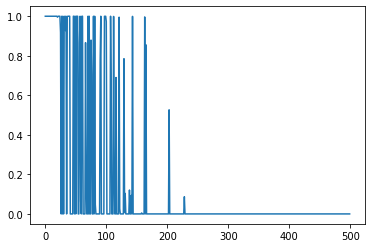

In [6]:
# teste da função de verificação
# de intensidade de sinal
coordA = 0, 0
data = list()
for i in np.arange(0, 500, 1):
    coordB = 0, i
    rssi = compute_rssi(coordA, coordB)
    pdr = convert_rssi_to_pdr(rssi)
    data.append(pdr)
plt.plot(data)

In [57]:
topology = json.load(open('topology.json', 'r'))
grid_data = json.load(open('force.json', 'r'))

In [58]:
topology['agents'][:2]

[{&#39;id&#39;: 7,
  &#39;name&#39;: &#39;prosumer7@10.0.0.1:1234&#39;,
  &#39;network&#39;: &#39;subnetwork-1&#39;,
  &#39;coordinates&#39;: [34, 36]},
 {&#39;id&#39;: 8,
  &#39;name&#39;: &#39;prosumer8@10.0.0.2:1235&#39;,
  &#39;network&#39;: &#39;subnetwork-1&#39;,
  &#39;coordinates&#39;: [46, 49]}]

In [59]:
grid_data['transformers'][:2]

[{&#39;name&#39;: &#39;trafo_2_7&#39;,
  &#39;source&#39;: 2,
  &#39;target&#39;: 7,
  &#39;power&#39;: 112.5,
  &#39;nodes&#39;: [7, 8, 9, 10, 11, 12, 13, 14],
  &#39;bess_nodes&#39;: [10, 12]},
 {&#39;name&#39;: &#39;trafo_3_15&#39;,
  &#39;source&#39;: 3,
  &#39;target&#39;: 15,
  &#39;power&#39;: 75,
  &#39;nodes&#39;: [15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26],
  &#39;bess_nodes&#39;: [25, 19, 21]}]

In [102]:
aux1 = list()
link_index = 1
nodes_qtd = len(grid_data['nodes']) + 2  # nodes qtd + dso agent + market agent
adj_array = np.zeros((nodes_qtd, nodes_qtd))

# definição do link físico de conexão do dso agent     
adj_array[nodes_qtd - 2, 0] = 1
adj_array[0, nodes_qtd - 2] = 1
aux2 = {'link-id': link_index,
        'source-id': 0,
        'target-id': nodes_qtd - 1}
aux1.append(aux2)
link_index += 1

# definição do link físico de conexão do market agent     
adj_array[nodes_qtd - 1, 0] = 1
adj_array[0, nodes_qtd - 1] = 1
aux2 = {'link-id': link_index,
        'source-id': 0,
        'target-id': nodes_qtd - 1 + 1}
aux1.append(aux2)
link_index += 1

# conexao dos nós 0-1 que não são nem concentradores nem prosumidores
adj_array[0, 1] = 1
adj_array[1, 0] = 1
aux2 = {'link-id': link_index,
        'source-id': 0,
        'target-id': 1}
aux1.append(aux2)
link_index += 1


agents_data = {a['id']: a for a in topology['agents']}
# percorre cada um dos concentradores e dos seus nós
links = dict()
for t in tqdm.tqdm_notebook(grid_data['transformers']):
    concent = t['source']
    nodes = t['nodes']
    # percorre cada um dos nós do concentrador
    for n in nodes:
        n_links = list()
        min_dist = (None, np.inf)
        coord_n = agents_data[n]['coordinates']
        # print('node: {}, coords: x: {}, y: {}'.format(n, coord_n[0], coord_n[1]))
        for m in nodes:
            if m != n:
                coord_m = agents_data[m]['coordinates']
                dist = np.linalg.norm(np.array(coord_n) - np.array(coord_m))
                # print('Dist beetween nodes {} and {}: {:5.3f}'.format(n, m, dist))
                
                # verifica a conexão entre os nós n e m
                if test_link(coord_n, coord_m):
                    n_links.append(m)

                    adj_array[n, m] = 1
                    adj_array[m, n] = 1
                    aux2 = {'link-id': link_index,
                            'source-id': n,
                            'target-id': m}
                    aux1.append(aux2)
                    link_index += 1
                
                # armazena a menor distancia entre os nós
                if dist < min_dist[1]:
                    min_dist = (m, dist) 

        # garante que sempre haverá pelo menos um link
        if not n_links:
            n_links.append(min_dist[0])
            
            adj_array[n,  min_dist[0]] = 1
            adj_array[ min_dist[0], n] = 1
            aux2 = {'link-id': link_index,
                    'source-id': n,
                    'target-id': min_dist[0]}
            aux1.append(aux2)
            link_index += 1

        links[n] = n_links

    # verifica as conexões dos nós com o concentrador 
    n_links = list()
    min_dist = (None, np.inf)
    coord_c = agents_data[concent]['coordinates']
    # print('concentrator : {}, coords: x: {}, y: {}'.format(concent, coord_c[0], coord_c[1]))
    
    # garante a conexão direta do nó concent com o nó 0, ou seja, o nó da SE
    adj_array[0, concent] = 1
    adj_array[concent, 0] = 1
    aux2 = {'link-id': link_index,
            'source-id': 0,
            'target-id': concent}
    aux1.append(aux2)
    link_index += 1
    
    for m in nodes:
        coord_m = agents_data[m]['coordinates']
        dist = np.linalg.norm(np.array(coord_c) - np.array(coord_m))
        # print('Dist beetween nodes {} and {}: {}'.format(concent, m, dist))

        # verifica a conexão entre os nós concent e m
        if test_link(coord_c, coord_m):
            n_links.append(m)

            adj_array[concent, m] = 1
            adj_array[m, concent] = 1
            aux2 = {'link-id': link_index,
                    'source-id': concent,
                    'target-id': m}
            aux1.append(aux2)
            link_index += 1
                
        # armazena a menor distancia entre os nós
        if dist < min_dist[1]:
            min_dist = (m, dist)
    # garante que sempre haverá pelo menos um link
    if not n_links:
        n_links.append(min_dist[0])

        adj_array[concent, min_dist[0]] = 1
        adj_array[min_dist[0], concent] = 1
        aux2 = {'link-id': link_index,
                'source-id': concent,
                'target-id': min_dist[0]}
        aux1.append(aux2)
        link_index += 1
    
    links[concent] = n_links